<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Título del proyecto -->
            Prospectivity for "U - REE" - Peru Central
        </strong>
    </span>
    <br>
    <span style="font-size:16px">
        ¿Coinciden los datos públicos? Validación de fuentes de gravimetría y de uranio en roca
    </span>
    <br><br>
    <span>
        <!-- Repositorio del proyecto -->
        <a href="https://github.com/HeisenbergPy/Prospectivity-for-U-REE-Peru-Central" target="_blank">
            <img src="https://img.shields.io/badge/GitHub-repositorio-181717?logo=github">
        </a>
        &nbsp;&nbsp;
        <!-- Versión de Python -->
        <img src="https://img.shields.io/badge/Python-3.12-3776AB?logo=python&logoColor=white">
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/badge/licencia-MIT-forestgreen">
        &nbsp;&nbsp;
        <!-- Entorno -->
        <img src="https://img.shields.io/badge/entorno-uv-de5fe9">
    </span>
    <br>
    <span>
        <!-- Curso -->
        <img src="https://img.shields.io/badge/PUCP-Geocomputaci%C3%B3n%201GEO20-1d3557">
        &nbsp;&nbsp;
        <!-- Semestre -->
        <img src="https://img.shields.io/badge/semestre-2026--II-e8761a">
    </span>
    <br>
    <span>
        <strong>Carlos Manuel Gutiérrez Cruzado</strong> &nbsp;|&nbsp; <strong>Félix Bryan Cordero Escobar</strong>
    </span>
    <br>
    <span>Pontificia Universidad Católica del Perú</span>
</div>

***

<span style="color:#e8761a; font-size:25px">**GC02 - Validación de las fuentes**</span>

Entrega final del Trabajo Final de **Geocomputación (1GEO20)**, semestre 2026-II.

Este cuaderno responde las dos primeras preguntas del trabajo: si el modelo global de gravedad
<span style="color:#2a9d8f">XGM2019e</span> reproduce la anomalía de Bouguer de las estaciones de INGEMMET y si el
<span style="color:#2a9d8f">uranio en roca</span> medido por distintas instituciones es comparable. Parte de lo
observado en GC01 y pone a prueba sus hipótesis.

<span style="color:#2a9d8f; font-size:20px">**Contenido**</span>

***
- [Descripción general](#descripcion)
- [1. Librerías y datos](#parte-1)
- **Parte A. Anomalía de Bouguer: estaciones frente a modelo**
  - [2. Cómo se redujeron las estaciones](#parte-2)
  - [3. Síntesis del modelo XGM2019e](#parte-3)
  - [4. Altura a la que se evalúa el modelo](#parte-4)
  - [5. Corrección de terreno aproximada](#parte-5)
- **Parte B. Uranio en roca: cinco fuentes**
  - [6. Depuración de las muestras](#parte-6)
  - [7. Pares de muestras y distancia](#parte-7)
  - [8. ¿El desacuerdo depende de la concentración?](#parte-8)
  - [9. Método analítico y tipo de roca](#parte-9)
- [10. Conclusiones de la validación](#parte-10)
- [Declaración de uso de inteligencia artificial](#ia)
- [Referencias](#referencias)

***

<a id="descripcion"></a>

## <span style="color:#e8761a">**DESCRIPCIÓN GENERAL**</span>
***

### Objetivo

Determinar en qué medida concuerdan las fuentes de una misma variable y explicar por qué difieren donde lo hacen:

1. **Anomalía de Bouguer.** En GC01, el modelo XGM2019e reprodujo el patrón regional de las estaciones (r = 0,80),
   con un error típico de 44,7 mGal y dos grupos de estaciones altas con diferencias de signo opuesto, que se
   atribuyeron provisionalmente a la campaña de medición. Aquí se reconstruye la reducción de las estaciones, se
   calcula el modelo con una síntesis armónica propia a la altura real de cada estación y se estima la corrección
   de terreno.
2. **Uranio en roca.** En GC01, la litogeoquímica y BDG 2022 mostraron una razón mediana de 1,3 en 16 pares, sin
   significación al 5 %. Aquí se depuran las muestras (vetas, menas y réplicas), se examina la sensibilidad a la
   distancia del par y se separa el efecto del método analítico y del tipo de roca.

| Técnica | Para qué se usa | Sección |
|---|---|---|
| Reconstrucción de la reducción de Bouguer | Saber qué representa el dato publicado | 2 |
| Síntesis armónica (grado 2190) en puntos | Evaluar el modelo donde se midió | 3 y 4 |
| Corrección de terreno con el DEM | Poner ambas fuentes en la misma definición | 5 |
| Sesgo, RMS, correlación y Bland-Altman | Medir el acuerdo y si depende del nivel | 4, 5 y 8 |
| Pares únicos, Wilcoxon y bootstrap | Comparar fuentes en el mismo afloramiento | 7 |
| Kruskal-Wallis y Mann-Whitney | Comparar métodos y clases de roca | 9 |

<a id="parte-1"></a>

## <span style="color:#e8761a">**1. LIBRERÍAS Y DATOS**</span>
***

Además de los módulos de GC01, este cuaderno emplea `geocomp/gravedad.py`, con la síntesis armónica del modelo, la
reducción de las estaciones y la corrección de terreno.

In [1]:
'''Importamos las librerías que usaremos'''

import numpy as np                           # Cálculo numérico
import pandas as pd                          # Tablas
from scipy import stats                      # Pruebas estadísticas
import matplotlib.pyplot as plt              # Gráficos
from matplotlib.colors import TwoSlopeNorm   # Escala de color centrada en 0
'''Funciones propias del trabajo (carpeta geocomp/)'''
from geocomp import lectura, espacial, estadistica, gravedad
from geocomp import graficos as graf
from geocomp.rutas import ARCHIVOS

'''Estilo común de las figuras'''
graf.aplicar_estilo()
pd.set_option('display.precision', 2)

Se cargan las estaciones, el relieve y las cinco fuentes de U. La capa de estaciones de GEOCATMIN trae la gravedad
observada y la anomalía de Bouguer, pero no la cota de la estación, de modo que se toma la del DEM:

In [2]:
'''Área de estudio, estaciones gravimétricas y relieve (DEM en UTM con celdas de 250 m)'''
aoi = lectura.cargar_aoi()
estaciones = lectura.cargar_gravedad_estaciones()
elevacion, extension = espacial.raster_a_utm(ARCHIVOS['dem_90m'], aoi, celda=250)

'''Cota de cada estación según el DEM de 90 m (GEOCATMIN no publica la cota de la estación)'''
estaciones['elevacion_m'] = espacial.muestrear_raster(ARCHIVOS['dem_90m'], estaciones)

'''Uranio en roca de las cinco fuentes'''
uranio = lectura.cargar_uranio()
print(f'Estaciones: {len(estaciones)} | muestras de U: {len(uranio)}')

Estaciones: 192 | muestras de U: 810


***

<a id="parte-2"></a>

## <span style="color:#e8761a">**2. CÓMO SE REDUJERON LAS ESTACIONES**</span>
***

La anomalía de Bouguer simple de una estación se obtiene de la gravedad observada *g*, de la gravedad normal γ en la
latitud de la estación y de su cota *h* (LaFehr, 1991):

$$\Delta g_B = g - \gamma(\varphi) + 0{,}3086\,h - 2\pi G\rho\,h$$

El primer término de corrección lleva la medición al nivel del mar (aire libre) y el segundo resta la atracción de
una placa de roca de densidad ρ y espesor *h*. GEOCATMIN no indica qué fórmula de γ, qué densidad ni qué cota se
usaron. Si al recalcular la anomalía con la Fórmula Internacional de 1967, ρ = 2670 kg/m³ y la cota del DEM se
obtiene el valor publicado, esa es la reducción aplicada, y se sabe además si incluye la corrección de terreno.

In [3]:
'''Latitud de cada estación: la gravedad normal depende de ella'''
latitud = estaciones.to_crs('EPSG:4326').geometry.y.values

'''Recalculamos la anomalía con la cota del DEM, la Fórmula Internacional de 1967 y ρ = 2670 kg/m³'''
estaciones['bouguer_recalculada'] = gravedad.bouguer_simple(estaciones.gravedad_mgal, latitud, estaciones.elevacion_m)
estaciones['residuo_mgal'] = estaciones.bouguer_mgal - estaciones.bouguer_recalculada

'''Un residuo de 1 mGal equivale a unos 5 m de cota (1 / 0,1966 mGal/m)'''
GRADIENTE_BOUGUER = gravedad.GRADIENTE_AIRE_LIBRE - gravedad.GRADIENTE_PLACA
estaciones['residuo_cota_m'] = estaciones.residuo_mgal / GRADIENTE_BOUGUER

estaciones[['bouguer_mgal', 'bouguer_recalculada', 'residuo_mgal', 'residuo_cota_m']].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

,bouguer_mgal,bouguer_recalculada,residuo_mgal,residuo_cota_m
count,192.00,192.00,192.00,192.00
mean,-259.66,-259.69,0.03,0.16
std,49.63,95.51,84.94,431.98
min,-368.49,-906.29,-226.18,-1150.27
5%,-355.25,-360.29,-50.52,-256.91
25%,-286.96,-291.03,-15.57,-79.16
50%,-260.62,-259.80,-2.92,-14.86
75%,-215.93,-193.63,1.16,5.92
95%,-185.73,-166.01,28.34,144.14
max,-176.39,-23.13,692.79,3523.28


La mayoría de las estaciones queda muy cerca del valor publicado, pero el máximo supera los 600 mGal. Se separan las
estaciones con un residuo mayor que 100 mGal, que equivaldría a un error de cota de unos 500 m:

In [4]:
'''Estaciones cuya gravedad observada no concuerda con su propia anomalía publicada (residuo > 100 mGal)'''
incoherente = estaciones.residuo_mgal.abs() > 100

'''Gravedad observada de la estación coherente más cercana, como referencia'''
vecina = espacial.vecino_mas_cercano(estaciones[incoherente], estaciones[~incoherente], ['OBJECTID', 'gravedad_mgal'])
pd.DataFrame({
    'OBJECTID': estaciones.loc[incoherente, 'OBJECTID'],
    'g observada (mGal)': estaciones.loc[incoherente, 'gravedad_mgal'],
    'g de la vecina (mGal)': vecina.gravedad_mgal,
    'distancia a la vecina (km)': vecina.dist_vecino_m / 1000,
    'Bouguer publicada': estaciones.loc[incoherente, 'bouguer_mgal'],
    'residuo (mGal)': estaciones.loc[incoherente, 'residuo_mgal'],
})

,OBJECTID,g observada (mGal),g de la vecina (mGal),distancia a la vecina (km),Bouguer publicada,residuo (mGal)
108,3342,977089.07,977782.41,0.77,-208.96,658.44
109,3354,977076.75,977782.41,2.08,-213.50,692.79
110,3366,977215.38,977756.94,0.79,-214.77,537.04
164,3618,977413.99,977392.38,1.88,-249.31,-226.18
166,3620,977430.95,977474.18,1.79,-256.43,-100.04


Si la reducción es la misma, el residuo restante debería deberse a la cota: las coordenadas de la estación tienen un
error de algunas decenas de metros, y en una ladera empinada ese desplazamiento cambia la cota del DEM. Se compara el
residuo con la pendiente del terreno:

In [5]:
'''Pendiente del terreno (grados) en la grilla de 250 m del DEM'''
dz_dy, dz_dx = np.gradient(elevacion, 250)
pendiente = np.degrees(np.arctan(np.hypot(dz_dx, dz_dy)))

'''Pendiente de la celda que contiene a cada estación'''
fila = ((extension[3] - estaciones.geometry.y) // 250).astype(int)
columna = ((estaciones.geometry.x - extension[0]) // 250).astype(int)
estaciones['pendiente_grados'] = pendiente[fila, columna]

'''Residuo según la pendiente (sin las 3 estaciones incoherentes)'''
coherentes = estaciones[~incoherente]
CLASES_PENDIENTE = pd.cut(coherentes.pendiente_grados, [0, 10, 20, 90], labels=['< 10°', '10-20°', '> 20°'])
coherentes.groupby(CLASES_PENDIENTE, observed=True).residuo_mgal.agg(
    estaciones='size', mediana='median',
    dentro_de_5_mGal=lambda r: 100 * (r.abs() <= 5).mean(),
    P90_absoluto=lambda r: r.abs().quantile(0.9),
)

,estaciones,mediana,dentro_de_5_mGal,P90_absoluto
pendiente_grados,,,,
< 10°,72,-0.56,80.56,7.58
10-20°,53,-5.73,28.30,40.97
> 20°,62,-13.94,9.68,49.81


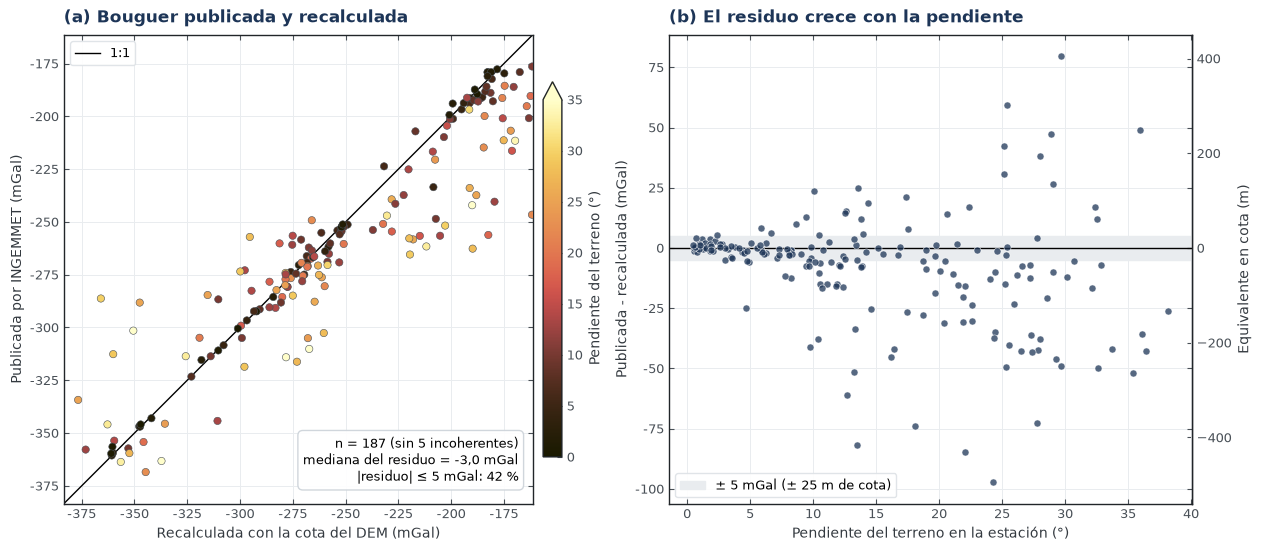

In [6]:
'''Figura 1: (a) Bouguer publicada frente a la recalculada y (b) residuo según la pendiente'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.4), layout='constrained')

'''(a) Si la reducción fuera la misma, los puntos caerían sobre la diagonal 1:1'''
lim = np.array([coherentes.bouguer_mgal.min() - 15, coherentes.bouguer_mgal.max() + 15])
ax1.plot(lim, lim, color='black', lw=1, label='1:1')
puntos = ax1.scatter(
    coherentes.bouguer_recalculada, coherentes.bouguer_mgal, c=coherentes.pendiente_grados,
    cmap='cmc.lajolla', vmin=0, vmax=35, s=28, edgecolor='#495057', lw=0.4, zorder=3,
)
ax1.set(xlim=lim, ylim=lim, xlabel='Recalculada con la cota del DEM (mGal)', ylabel='Publicada por INGEMMET (mGal)')
ax1.set_aspect('equal')
ax1.legend(loc='upper left')
graf.cuadro_texto(
    ax1,
    f'n = {len(coherentes)} (sin {incoherente.sum()} incoherentes)\n'
    f'mediana del residuo = {graf.numero_es(coherentes.residuo_mgal.median())} mGal\n'
    f'|residuo| ≤ 5 mGal: {graf.numero_es(100 * (coherentes.residuo_mgal.abs() <= 5).mean(), 0)} %',
)
fig.colorbar(puntos, ax=ax1, shrink=0.8, pad=0.02, label='Pendiente del terreno (°)', extend='max')
ax1.set_title('(a) Bouguer publicada y recalculada')

'''(b) Residuo frente a pendiente, con su equivalente en metros de cota en el eje derecho'''
ax2.axhspan(-5, 5, color='#e9ecef', zorder=0, label='± 5 mGal (± 25 m de cota)')
ax2.axhline(0, color='black', lw=1)
ax2.scatter(coherentes.pendiente_grados, coherentes.residuo_mgal, s=26, color=graf.AZUL, alpha=0.75,
            edgecolor='white', lw=0.5, zorder=3)
ax2.set(xlabel='Pendiente del terreno en la estación (°)', ylabel='Publicada - recalculada (mGal)')
eje_cota = ax2.secondary_yaxis('right', functions=(lambda v: v / GRADIENTE_BOUGUER, lambda v: v * GRADIENTE_BOUGUER))
eje_cota.set_ylabel('Equivalente en cota (m)')
ax2.legend(loc='lower left')
ax2.set_title('(b) El residuo crece con la pendiente')

for ax in (ax1, ax2):
    graf.ejes_coma_decimal(ax)

graf.guardar(fig, 'GC02_01_reduccion_estaciones.png', svg=True)

**Lectura:** en terreno llano (pendiente < 10°), la anomalía recalculada coincide con la publicada: la mediana del
residuo es de −0,6 mGal y el 81 % de las estaciones queda a menos de 5 mGal, unos 25 m de cota. INGEMMET publica, por
tanto, una anomalía de Bouguer **simple**, calculada con la Fórmula Internacional de 1967 y ρ = 2670 kg/m³. Si
incluyera la corrección de terreno, el residuo sería positivo donde el relieve es abrupto, porque esa corrección
siempre suma; ocurre lo contrario: con pendientes mayores de 20°, la mediana es de −13,9 mGal. La explicación es
geométrica: las estaciones están en carreteras de fondo de valle, y la celda de 90 m del DEM promedia la ladera, más
alta que la vía; con una cota mayor, la anomalía recalculada resulta mayor que la publicada.

Cinco estaciones presentan residuos mayores que 100 mGal:
- en tres (3342, 3354 y 3366), la gravedad observada es de 540 a 700 mGal menor que la de su vecina a menos de
  2 km, mientras que su anomalía publicada concuerda con la de las estaciones vecinas: el error está en el campo de
  la gravedad observada (`GRAV_MGAL`), probablemente de transcripción, y no en la anomalía (`BOUG_MGAL`);
- en las otras dos (3618 y 3620), la gravedad concuerda con la de la vecina, y el residuo de −226 y −100 mGal
  equivaldría a una cota de 500 a 1150 m menor que la del DEM; con estos datos no puede determinarse la cota correcta.

> Consecuencia para la validación: la anomalía publicada es utilizable en las 192 estaciones, pero es una anomalía
> simple, sin corrección de terreno, y así debe compararse con el modelo.

***

<a id="parte-3"></a>

## <span style="color:#e8761a">**3. SÍNTESIS DEL MODELO XGM2019E**</span>
***

La grilla del modelo incluida en `datos/` y los valores del modelo en las estaciones se calculan con el script
[`scripts/sintesis_xgm2019e.py`](../scripts/sintesis_xgm2019e.py), que descarga los coeficientes oficiales de ICGEM
(420 MB) y aplica la síntesis armónica de `geocomp/gravedad.py`:

$$\Delta g = \frac{GM}{r^2} \sum_{n=0}^{2190} (n-1) \left(\frac{a}{r}\right)^{n} \sum_{m=0}^{n}
\bar{P}_{nm}(\sin\psi) \left[\Delta\bar{C}_{nm} \cos m\lambda + \bar{S}_{nm} \sin m\lambda\right]$$

donde ψ es la latitud geocéntrica, *r* la distancia al centro de la Tierra y ΔC̄ los coeficientes del modelo menos
los del elipsoide GRS80 (Barthelmes, 2013). La anomalía de Bouguer resta la placa con la topografía del modelo
etopo1-2250 truncada al mismo grado.

```bash
uv run python scripts/sintesis_xgm2019e.py
```

| Control | Resultado |
|---|---|
| Grilla de `datos/` (3339 nodos) | diferencia máxima de 0,00002 mGal |
| Estadísticas publicadas por ICGEM para la misma grilla | mínimo −424,461 frente a −424,456 mGal; máximo −13,512 frente a −13,506 mGal |
| Topografía del modelo frente a ICGEM | mínimo 155,748 m y máximo 4866,929 m en ambos |
| Funciones de Legendre y campo normal | pruebas en `tests/test_gravedad.py` (SciPy y J₄ del GRS80) |

La síntesis tarda unos 40 s, pero requiere los 420 MB de coeficientes; por ello el cuaderno lee la tabla que deja el
script (`datos/gravedad/xgm2019e_estaciones.csv`, registrada en el manifiesto). Para cada estación contiene la
ondulación del geoide N, la topografía del modelo H y la anomalía de Bouguer del modelo calculada sobre el elipsoide
(h = 0, como la grilla) y en la superficie (h = cota del DEM + N). El script deja también una segunda grilla,
evaluada en la superficie del propio modelo, que se emplea en GC03.

In [7]:
'''Valores del modelo en cada estación, calculados por scripts/sintesis_xgm2019e.py'''
modelo = pd.read_csv(ARCHIVOS['xgm2019e_estaciones'])
estaciones = estaciones.merge(modelo.drop(columns=['lon', 'lat', 'h_dem_m']), on='OBJECTID')
modelo.head()

,OBJECTID,lon,lat,h_dem_m,N_geoide_m,H_modelo_m,bouguer_h0_mgal,bouguer_superficie_mgal
0,2623,-74.74,-11.05,658.1,26.22,702.7,-168.22,-162.45
1,2848,-74.83,-11.51,2275.4,33.78,3008.5,-264.12,-230.91
2,2926,-74.68,-11.12,744.7,26.92,1065.8,-163.84,-164.61
3,2927,-75.38,-11.13,905.1,27.45,1208.1,-323.75,-298.41
4,2935,-75.39,-11.14,1058.6,27.65,1332.3,-332.51,-302.87


Como control, el valor puntual a h = 0 debe coincidir con la grilla interpolada en la estación, salvo el error propio
de interpolar una grilla de 2,8 km:

In [8]:
'''Control: el modelo calculado en la estación (h = 0) frente a la grilla del repositorio interpolada en ese punto'''
en_grilla = espacial.muestrear_raster(ARCHIVOS['gravedad_xgm2019e'], estaciones)
control = estaciones.bouguer_h0_mgal - en_grilla
print(f'Punto - grilla: mediana {graf.numero_es(np.median(control), 2)} mGal; '
      f'95 % entre {graf.numero_es(np.percentile(control, 2.5))} y {graf.numero_es(np.percentile(control, 97.5))} mGal')
print(f'Ondulación del geoide: {graf.numero_es(estaciones.N_geoide_m.min())} a {graf.numero_es(estaciones.N_geoide_m.max())} m')

Punto - grilla: mediana -0,41 mGal; 95 % entre -2,8 y 2,3 mGal
Ondulación del geoide: 25,2 a 36,4 m


***

<a id="parte-4"></a>

## <span style="color:#e8761a">**4. ALTURA A LA QUE SE EVALÚA EL MODELO**</span>
***

La grilla de GC01 se calculó sobre el elipsoide (h = 0), como en el servicio de grillas de ICGEM, pero las estaciones
miden en la superficie, a más de 4000 m en la puna. Un modelo armónico evaluado por debajo del lugar de medición
equivale a una **continuación hacia abajo**: cada grado *n* se multiplica por (*r*ₛ/*r*₀)ⁿ, con *r*ₛ y *r*₀ los
radios de la superficie y del elipsoide (Hofmann-Wellenhof y Moritz, 2006). La tabla muestra ese factor:

In [9]:
'''Factor que multiplica al término de grado n al bajar el cálculo h metros, del lugar de la estación al elipsoide'''
RADIO = 6_371_000
pd.DataFrame(
    {f'n = {n}': [(1 + h / RADIO) ** n for h in (500, 1000, 2000, 3000, 4000)] for n in (360, 719, 1500, 2190)},
    index=pd.Index([500, 1000, 2000, 3000, 4000], name='h (m)'),
)

,n = 360,n = 719,n = 1500,n = 2190
h (m),,,,
500,1.03,1.06,1.12,1.19
1000,1.06,1.12,1.27,1.41
2000,1.12,1.25,1.60,1.99
3000,1.18,1.40,2.03,2.80
4000,1.25,1.57,2.56,3.95


A 4000 m, el grado 2190 se amplifica casi cuatro veces, y es precisamente la parte del modelo que sobre los
continentes proviene de la topografía y no de gravedad medida (Zingerle et al., 2020). Se compara el acuerdo con las
estaciones en ambas alturas:

In [10]:
'''Dos formas de evaluar el mismo modelo'''
VARIANTES = {
    'Modelo sobre el elipsoide (h = 0)': 'bouguer_h0_mgal',
    'Modelo en la superficie': 'bouguer_superficie_mgal',
}
acuerdo = pd.DataFrame({
    nombre: estadistica.metricas_acuerdo(estaciones.bouguer_mgal, estaciones[columna])
    for nombre, columna in VARIANTES.items()
}).T
acuerdo[['n', 'sesgo', 'desv', 'rms', 'r', 'rho']]

,n,sesgo,desv,rms,r,rho
Modelo sobre el elipsoide (h = 0),192.0,11.53,44.08,45.45,0.80,0.80
Modelo en la superficie,192.0,20.05,26.32,33.03,0.88,0.86


In [11]:
'''Diferencia modelo - estación por clase de elevación de la estación'''
CLASES_ELEVACION = pd.cut(estaciones.elevacion_m, [0, 1000, 2000, 3000, 4500],
                          labels=['< 1000 m', '1000-2000 m', '2000-3000 m', '> 3000 m'])
diferencias = {nombre: estaciones[columna] - estaciones.bouguer_mgal for nombre, columna in VARIANTES.items()}
por_elevacion = pd.concat(
    {nombre: d.groupby(CLASES_ELEVACION, observed=True).agg(estaciones='size', sesgo='mean', desv='std')
     for nombre, d in diferencias.items()}, axis=1)
por_elevacion

Modelo sobre el elipsoide (h = 0)                \
                                   estaciones  sesgo   desv   
elevacion_m                                                   
< 1000 m                                   84  23.98  21.61   
1000-2000 m                                43  17.42  33.70   
2000-3000 m                                 8  -6.43  10.03   
> 3000 m                                   57  -8.72  65.93   

            Modelo en la superficie                
                         estaciones  sesgo   desv  
elevacion_m                                        
< 1000 m                         84  32.61  21.10  
1000-2000 m                      43  32.79  22.91  
2000-3000 m                       8  25.92   4.88  
> 3000 m                         57  -8.90   9.32

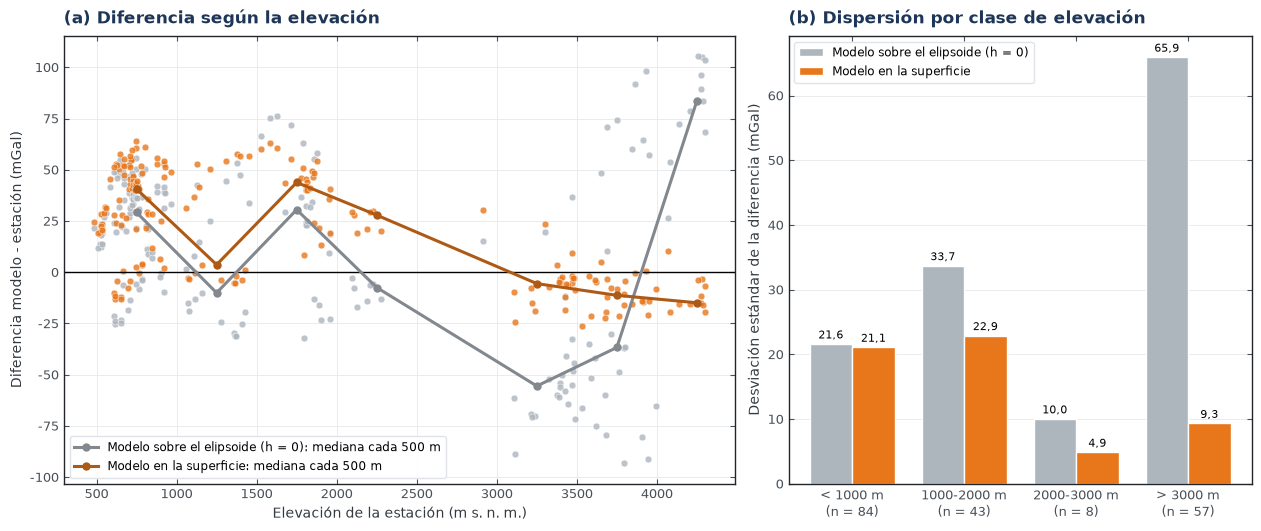

In [12]:
'''Figura 2: diferencia modelo - estación según la elevación, con el modelo en el elipsoide y en la superficie'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={'width_ratios': [1.45, 1]}, layout='constrained')
COLORES_VARIANTE = {'Modelo sobre el elipsoide (h = 0)': '#adb5bd', 'Modelo en la superficie': graf.NARANJA}

'''(a) Cada estación dos veces: gris = modelo a h = 0; naranja = modelo en la superficie'''
tramo = (estaciones.elevacion_m // 500) * 500 + 250
ax1.axhline(0, color='black', lw=1)
for nombre, d in diferencias.items():
    color = COLORES_VARIANTE[nombre]
    ax1.scatter(estaciones.elevacion_m, d, s=24, color=color, alpha=0.8, edgecolor='white', lw=0.4)
    mediana = d.groupby(tramo).agg(['median', 'size']).query('size >= 5')['median']
    ax1.plot(mediana.index, mediana.values, color=graf.oscurecer(color, 0.25), lw=2.2, marker='o', ms=5,
             label=f'{nombre}: mediana cada 500 m')
ax1.set(xlabel='Elevación de la estación (m s. n. m.)', ylabel='Diferencia modelo - estación (mGal)')
ax1.legend(loc='lower left', fontsize=8.5)
ax1.set_title('(a) Diferencia según la elevación')

'''(b) Dispersión de la diferencia (desviación estándar) en cada clase de elevación'''
ancho = 0.38
for k, nombre in enumerate(VARIANTES):
    desv = por_elevacion[(nombre, 'desv')]
    barras = ax2.bar(np.arange(len(desv)) + (k - 0.5) * ancho, desv.values, ancho, color=COLORES_VARIANTE[nombre],
                     edgecolor='white', label=nombre)
    ax2.bar_label(barras, labels=[graf.numero_es(v) for v in desv.values], fontsize=8, padding=2)
ax2.set_xticks(range(len(desv)), [f'{c}\n(n = {n})' for c, n in zip(desv.index, por_elevacion.iloc[:, 0])])
ax2.set(ylabel='Desviación estándar de la diferencia (mGal)')
ax2.grid(axis='x', visible=False)
ax2.legend(loc='upper left', fontsize=8.5)
ax2.set_title('(b) Dispersión por clase de elevación')

for ax in (ax1, ax2):
    graf.ejes_coma_decimal(ax, x=ax is ax1)

graf.guardar(fig, 'GC02_02_altura_del_modelo.png', svg=True)

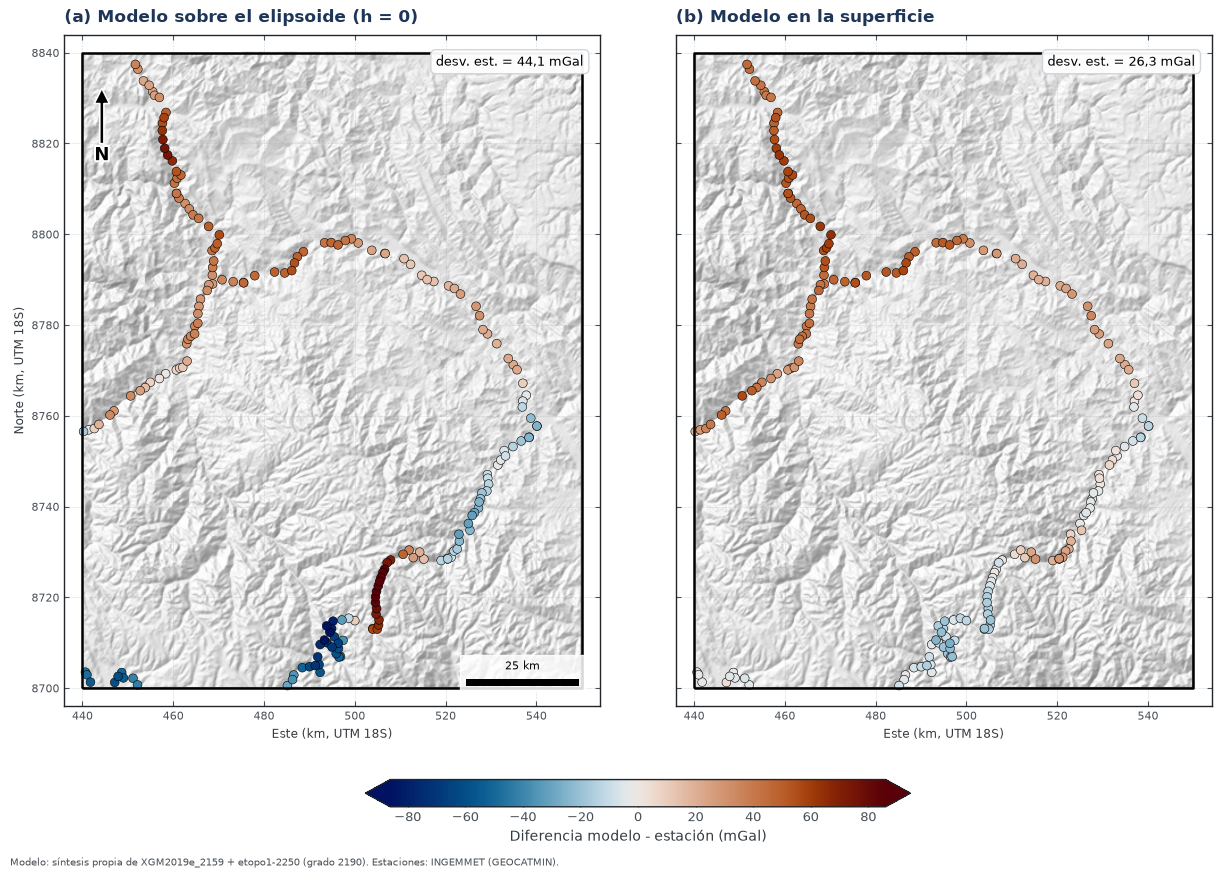

In [13]:
'''Figura 3: mapas de la diferencia con el modelo en el elipsoide y en la superficie (misma escala de color)'''

limite = np.nanpercentile(np.abs(diferencias['Modelo sobre el elipsoide (h = 0)']), 95)
norma = TwoSlopeNorm(0, -limite, limite)
fig, ejes = plt.subplots(1, 2, figsize=(12.5, 8.4), sharey=True, layout='constrained')

for ax, (nombre, d), letra in zip(ejes, diferencias.items(), 'ab'):
    graf.relieve(ax, elevacion, extension, opacidad=0.6)
    orden = d.abs().sort_values().index                      # las diferencias grandes, encima
    puntos = ax.scatter(estaciones.geometry.x[orden], estaciones.geometry.y[orden], c=d[orden],
                        cmap=graf.CMAP_DIVERGENTE, norm=norma, s=40, edgecolor='black', lw=0.4, zorder=10)
    graf.marco_mapa(ax, aoi, f'({letra}) {nombre}', accesorios=letra == 'a')
    graf.cuadro_texto(ax, f'desv. est. = {graf.numero_es(d.std())} mGal', x=0.97, y=0.97, va='top')
ejes[1].set_ylabel('')

barra = fig.colorbar(puntos, ax=list(ejes), orientation='horizontal', shrink=0.45, extend='both')
barra.set_label('Diferencia modelo - estación (mGal)')
graf.fuente_figura(fig, 'Modelo: síntesis propia de XGM2019e_2159 + etopo1-2250 (grado 2190). Estaciones: INGEMMET (GEOCATMIN).')

graf.guardar(fig, 'GC02_03_mapas_diferencia.png')

**Lectura:** evaluar el modelo en la superficie, y no sobre el elipsoide, reduce la dispersión de la diferencia de
44,1 a 26,3 mGal y eleva la correlación de 0,80 a 0,88. La mejora se concentra en las estaciones altas: por encima
de 3000 m, la desviación estándar baja de 65,9 a 9,3 mGal y los dos grupos de signo opuesto de GC01 desaparecen
(figura 3). No eran, por tanto, un efecto de la campaña de medición, como se planteó en GC01, sino de calcular el
modelo 3 a 4 km por debajo de las estaciones, donde la continuación hacia abajo multiplica por 2 a 4 los grados más
altos del modelo.

Por debajo de 2000 m, en cambio, la altura de cálculo casi no cambia la dispersión (21 a 23 mGal), y el modelo
queda unos 33 mGal por encima de las estaciones. Ese sesgo no depende de la altura de evaluación y se examina en la
sección siguiente.

> La grilla a h = 0 sirve para representar el patrón regional, pero para validar el modelo con mediciones de
> superficie hay que evaluarlo donde se midió.

***

<a id="parte-5"></a>

## <span style="color:#e8761a">**5. CORRECCIÓN DE TERRENO APROXIMADA**</span>
***

La anomalía de las estaciones es simple: la placa supone un terreno plano a la altura de la estación. Los cerros que
rodean la estación (masa de más, encima) y los valles (masa de menos, debajo) reducen la gravedad medida respecto de
esa placa, y la **corrección de terreno** (Hammer, 1939) la devuelve; siempre suma. El modelo, en cambio, tiene una
resolución de unos 9 km y su topografía ya está suavizada, por lo que se aproxima más a una anomalía completa.

`gravedad.correccion_terreno` suma el efecto de cada celda del DEM de 250 m como una columna vertical hasta 20 km de
la estación (la zona M de Hammer llega a 21,9 km):

$$\delta g_T = G\rho \sum_{celdas} A \left(\frac{1}{r} - \frac{1}{\sqrt{r^2 + \Delta h^2}}\right)$$

> El DEM del repositorio llega solo hasta el borde del área. A menos de 20 km del borde falta parte del terreno y la
> corrección queda corta; por ello las métricas se calculan también solo con las estaciones interiores.

In [14]:
'''Corrección de terreno con el DEM de 250 m hasta 20 km alrededor de cada estación'''
estaciones['tc_mgal'] = gravedad.correccion_terreno(
    estaciones, estaciones.elevacion_m, ARCHIVOS['dem_90m'], aoi, celda=250, radio=20_000)

'''El DEM del repositorio termina en el borde del área: a menos de 20 km del borde la corrección queda corta'''
estaciones['dist_borde_km'] = estaciones.distance(aoi.boundary.union_all()) / 1000
interior = estaciones.dist_borde_km > 20

'''Cuánto aporta el anillo de 10 a 20 km en las estaciones interiores'''
tc_10km = gravedad.correccion_terreno(
    estaciones[interior], estaciones.elevacion_m[interior], ARCHIVOS['dem_90m'], aoi, celda=250, radio=10_000)
print(f'Estaciones interiores (a más de 20 km del borde): {interior.sum()} de {len(estaciones)}')
print(f'Corrección de terreno: mediana {graf.numero_es(estaciones.tc_mgal.median())} mGal, '
      f'máxima {graf.numero_es(estaciones.tc_mgal.max())} mGal')
print(f'Aporte de 10 a 20 km (interiores): mediana {graf.numero_es(np.median(estaciones.tc_mgal[interior] - tc_10km))} mGal')

Estaciones interiores (a más de 20 km del borde): 102 de 192
Corrección de terreno: mediana 9,9 mGal, máxima 40,7 mGal
Aporte de 10 a 20 km (interiores): mediana 2,5 mGal


In [15]:
'''Bouguer de las estaciones con la corrección de terreno (equivalente a una Bouguer completa)'''
estaciones['bouguer_completa'] = estaciones.bouguer_mgal + estaciones.tc_mgal

'''Acuerdo con el modelo en la superficie, sin y con la corrección, en todas y solo en las interiores'''
casos = {
    'Superficie (todas)': (estaciones.bouguer_mgal, estaciones),
    'Superficie + terreno (todas)': (estaciones.bouguer_completa, estaciones),
    'Superficie (interiores)': (estaciones.bouguer_mgal[interior], estaciones[interior]),
    'Superficie + terreno (interiores)': (estaciones.bouguer_completa[interior], estaciones[interior]),
}
acuerdo_terreno = pd.DataFrame({
    nombre: estadistica.metricas_acuerdo(medida, tabla.bouguer_superficie_mgal) for nombre, (medida, tabla) in casos.items()
}).T
acuerdo_terreno[['n', 'sesgo', 'desv', 'rms', 'r']]

,n,sesgo,desv,rms,r
Superficie (todas),192.0,20.05,26.32,33.03,0.88
Superficie + terreno (todas),192.0,8.15,26.61,27.76,0.87
Superficie (interiores),102.0,30.52,21.62,37.34,0.80
Superficie + terreno (interiores),102.0,17.95,23.51,29.49,0.75


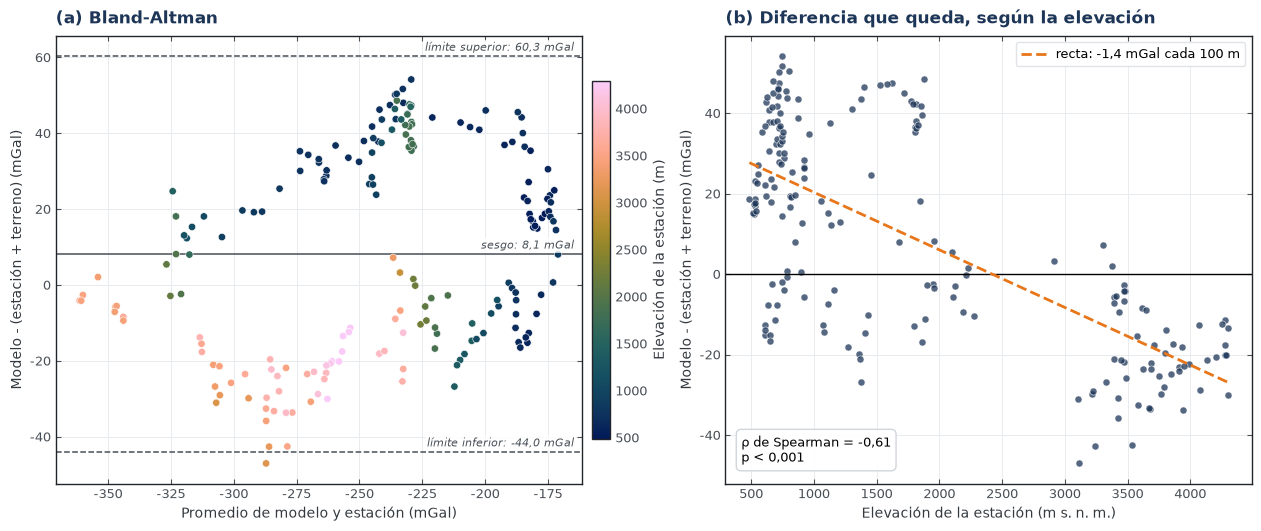

In [16]:
'''Figura 4: Bland-Altman del modelo en la superficie frente a la estación con corrección de terreno'''

ba = estadistica.bland_altman(estaciones.bouguer_completa, estaciones.bouguer_superficie_mgal)
rho_h, p_h = stats.spearmanr(estaciones.elevacion_m, ba['diferencia'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.2), layout='constrained')

'''(a) Diferencia frente al promedio de ambas fuentes: sesgo y límites de acuerdo al 95 %'''
puntos = ax1.scatter(ba['media'], ba['diferencia'], c=estaciones.elevacion_m, cmap='cmc.batlow', s=28,
                     edgecolor='white', lw=0.4, zorder=3)
for valor, texto, estilo in [(ba['sesgo'], 'sesgo', '-'), (ba['lim_inf'], 'límite inferior', '--'),
                             (ba['lim_sup'], 'límite superior', '--')]:
    graf.linea_ref(ax1, valor, f'{texto}: {graf.numero_es(valor)} mGal', pos=0.985, ls=estilo, color=graf.GRIS)
ax1.set(xlabel='Promedio de modelo y estación (mGal)', ylabel='Modelo - (estación + terreno) (mGal)')
fig.colorbar(puntos, ax=ax1, shrink=0.8, pad=0.02, label='Elevación de la estación (m)')
ax1.set_title('(a) Bland-Altman')

'''(b) Lo que queda: la diferencia disminuye con la elevación'''
ajuste = stats.linregress(estaciones.elevacion_m, ba['diferencia'])
x = np.array([estaciones.elevacion_m.min(), estaciones.elevacion_m.max()])
ax2.axhline(0, color='black', lw=1)
ax2.scatter(estaciones.elevacion_m, ba['diferencia'], s=26, color=graf.AZUL, alpha=0.75, edgecolor='white', lw=0.5)
ax2.plot(x, ajuste.intercept + ajuste.slope * x, color=graf.NARANJA, lw=2, ls='--',
         label=f'recta: {graf.numero_es(100 * ajuste.slope, 1)} mGal cada 100 m')
ax2.set(xlabel='Elevación de la estación (m s. n. m.)', ylabel='Modelo - (estación + terreno) (mGal)')
ax2.legend(loc='upper right')
graf.cuadro_texto(ax2, f'ρ de Spearman = {graf.numero_es(rho_h, 2)}\n{graf.texto_p(p_h)}', x=0.03, y=0.04, ha='left')
ax2.set_title('(b) Diferencia que queda, según la elevación')

for ax in (ax1, ax2):
    graf.ejes_coma_decimal(ax)

graf.guardar(fig, 'GC02_04_bland_altman_gravedad.png', svg=True)

**Lectura:** la corrección de terreno tiene una mediana de 9,9 mGal y alcanza 40,7 mGal en los valles más
profundos; el anillo de 10 a 20 km aporta solo 2,5 mGal en las estaciones interiores, por lo que el radio empleado es
suficiente. Al sumarla a las estaciones, el sesgo del modelo en la superficie baja de 20,1 a 8,2 mGal y el RMS de
33,0 a 27,8 mGal, pero la dispersión no cambia (26,3 frente a 26,6 mGal). En las estaciones interiores, donde la
corrección está completa, el sesgo baja de 30,5 a 18,0 mGal.

Queda una diferencia que disminuye con la elevación (ρ = −0,61; −1,4 mGal cada 100 m): el modelo supera a las
estaciones en unos 30 mGal en los valles de la selva alta (500 a 1000 m) y queda unos 20 mGal por debajo en la puna.
Los límites de acuerdo de Bland-Altman (−44 a +60 mGal) indican que, aun con la corrección, una estación individual
puede diferir del modelo en unos ±50 mGal.

Con estos datos no es posible atribuir esa tendencia a una sola causa. Dos explicaciones compatibles son:
1. por encima del grado 719, XGM2019e obtiene la gravedad de corta longitud de onda de la topografía y no de
   mediciones (Zingerle et al., 2020), de modo que en la transición entre la Cordillera Oriental y la faja subandina
   puede no representar la distribución real de densidades;
2. la corrección aproximada (columnas verticales, DEM de 250 m y radio de 20 km) subestima el efecto de los valles
   estrechos, donde se ubican las estaciones bajas.

Distinguirlas requeriría estaciones con cota medida (GNSS) y un DEM con margen fuera del área.

***

<a id="parte-6"></a>

## <span style="color:#e8761a">**6. DEPURACIÓN DE LAS MUESTRAS**</span>
***

En GC01 solo se excluyeron las muestras con Cu, Pb o Zn > 1000 ppm. Para comparar fuentes se requiere que ambas
representen el mismo material, por lo que `lectura.cargar_uranio` añade dos criterios descriptivos y
`lectura.rocas_de_caja` los aplica:

- `es_veta`: la propia fuente describe la muestra como veta, vetilla, mena o mineral de cancha (emplazamiento en la
  litogeoquímica, descripción geológica en GE27 y forma del cuerpo en el B-74);
- réplicas: dos análisis de la misma muestra (mismo código y mismo lugar) se unen en una fila con la media
  geométrica, para que esa roca no pese el doble;
- `en_labor_minera`: BDG 2022 proviene de la capa «roca_mena» de INGEMMET, y el campo `A_ITS` indica la mina o el
  prospecto donde se tomó cada muestra. No se excluye, pero se registra, porque condiciona la comparación con un
  muestreo regional como el de la litogeoquímica.

In [17]:
'''Rocas de caja: U medido, sin menas ni vetas y con las réplicas unidas (lectura.rocas_de_caja)'''
con_u = uranio[uranio.U_ppm.notna()]
rocas = lectura.rocas_de_caja(uranio)

'''Cuántas muestras quita cada criterio en cada fuente'''
def contar(tabla):
    return tabla.fuente.value_counts().reindex(lectura.FUENTES_U, fill_value=0)

depuracion = pd.DataFrame({
    'con U': contar(con_u),
    'mena (Cu, Pb o Zn > 1000 ppm)': contar(con_u[con_u.es_mena]),
    'veta o mena (descripción)': contar(con_u[con_u.es_veta & ~con_u.es_mena]),
    'réplicas unidas': contar(con_u[~con_u.es_mena & ~con_u.es_veta]) - contar(rocas),
    'rocas de caja': contar(rocas),
    'en labor minera': contar(rocas[rocas.en_labor_minera]),
})
depuracion.loc['total'] = depuracion.sum()
depuracion

,con U,"mena (Cu, Pb o Zn > 1000 ppm)",veta o mena (descripción),réplicas unidas,rocas de caja,en labor minera
fuente,,,,,,
Litogeoquímica,330,3,1,1,325,0
BDG 2022,234,26,0,0,208,185
GE27,45,0,13,0,32,0
IPEN,19,0,0,0,19,0
B-74,7,0,4,0,3,0
total,635,29,18,1,587,185


La única réplica corresponde a la litogeoquímica. Sus dos análisis permiten además estimar la repetibilidad del
laboratorio en una roca:

In [18]:
'''La réplica unida y los dos análisis originales'''
codigo_replica = rocas.loc[rocas.n_analisis > 1, 'codigo'].tolist()
print('Unida:', rocas.loc[rocas.n_analisis > 1, ['codigo', 'U_ppm', 'Th_ppm', 'SiO2_pct']].round(2).to_dict('records'))
originales = con_u[con_u.codigo.isin(codigo_replica)][['codigo', 'U_ppm', 'Th_ppm', 'SiO2_pct']]

'''El mismo código en dos lugares distintos: son dos rocas diferentes y se conservan'''
repetido = con_u[con_u.codigo.duplicated(keep=False) & ~con_u.codigo.isin(codigo_replica)]
separacion = repetido.geometry.iloc[0].distance(repetido.geometry.iloc[1]) / 1000
print(f'{repetido.codigo.iloc[0]}: dos muestras separadas {graf.numero_es(separacion)} km, '
      f'SiO2 {repetido.SiO2_pct.iloc[0]:.1f} y {repetido.SiO2_pct.iloc[1]:.1f} %')
originales

Unida: [{'codigo': '24m-GRB1-024', 'U_ppm': 7.37, 'Th_ppm': 27.19, 'SiO2_pct': 66.48}]
GR64A-19-104: dos muestras separadas 29,5 km, SiO2 45.4 y 64.4 %


,codigo,U_ppm,Th_ppm,SiO2_pct
254,24m-GRB1-024,6.1,26.6,66.14
268,24m-GRB1-024,8.9,27.8,66.82


***

<a id="parte-7"></a>

## <span style="color:#e8761a">**7. PARES DE MUESTRAS Y DISTANCIA**</span>
***

En GC01 se emplearon pares a menos de 250 m. Una distancia mayor aporta más pares, pero aumenta la probabilidad de
que las dos muestras sean rocas distintas. Si el desacuerdo entre fuentes es analítico, la razón B/A debe mantenerse
al aumentar la distancia; si es geológico, debe cambiar o dispersarse. Para cada umbral se calcula la razón mediana,
su intervalo de confianza del 90 % por remuestreo (`estadistica.intervalo_razon_mediana`, 2000 remuestreos con
semilla fija) y la prueba de Wilcoxon:

In [19]:
'''Pares únicos entre cada combinación de fuentes para varias distancias máximas'''
DISTANCIAS = [100, 250, 500, 1000, 2000]
filas = []
for i, a in enumerate(lectura.FUENTES_U):
    for b in lectura.FUENTES_U[i + 1:]:
        for distancia in DISTANCIAS:
            p = espacial.pares_cercanos(rocas[rocas.fuente == a], rocas[rocas.fuente == b], distancia_max=distancia)
            if len(p) < 3:
                continue
            u_a, u_b = rocas.loc[p.i_a, 'U_ppm'], rocas.loc[p.i_b, 'U_ppm']
            r = estadistica.comparar_pares_log(u_a, u_b)
            inferior, superior = estadistica.intervalo_razon_mediana(u_a, u_b)
            filas.append({
                'fuente A': a, 'fuente B': b, 'distancia máx. (m)': distancia, 'pares': r['n'],
                'razón mediana B/A': r['razon_mediana'], 'IC 90 % inf.': inferior, 'IC 90 % sup.': superior,
                'p de Wilcoxon': r['p_wilcoxon'],
            })
pares = pd.DataFrame(filas)
pares

,fuente A,fuente B,distancia máx. (m),pares,razón mediana B/A,IC 90 % inf.,IC 90 % sup.,p de Wilcoxon
0,Litogeoquímica,BDG 2022,100,8,1.52,0.81,3.82,0.31
1,Litogeoquímica,BDG 2022,250,16,1.34,0.90,3.24,0.07
2,Litogeoquímica,BDG 2022,500,26,1.34,0.90,2.38,0.08
3,Litogeoquímica,BDG 2022,1000,42,1.28,0.98,1.91,0.03
4,Litogeoquímica,BDG 2022,2000,55,1.17,0.95,1.52,0.06
5,Litogeoquímica,GE27,500,5,1.05,0.65,7.10,0.44
6,Litogeoquímica,GE27,1000,7,1.00,0.74,1.30,0.94
7,Litogeoquímica,GE27,2000,16,1.03,0.88,2.17,0.27
8,Litogeoquímica,IPEN,2000,4,1.59,1.23,36.36,NaN
9,BDG 2022,GE27,100,3,1.97,0.94,2.04,NaN


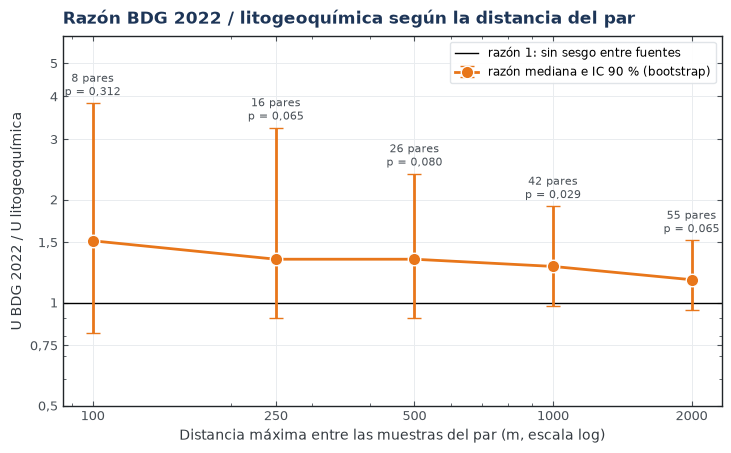

In [20]:
'''Figura 5: razón mediana BDG 2022 / litogeoquímica según la distancia máxima del par'''

lito_bdg = pares[(pares['fuente A'] == 'Litogeoquímica') & (pares['fuente B'] == 'BDG 2022')]
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.axhline(1, color='black', lw=1, label='razón 1: sin sesgo entre fuentes')
ax.errorbar(
    lito_bdg['distancia máx. (m)'], lito_bdg['razón mediana B/A'],
    yerr=[lito_bdg['razón mediana B/A'] - lito_bdg['IC 90 % inf.'], lito_bdg['IC 90 % sup.'] - lito_bdg['razón mediana B/A']],
    fmt='o-', color=graf.NARANJA, mec='white', ms=9, lw=2, capsize=5, label='razón mediana e IC 90 % (bootstrap)',
)
for _, f in lito_bdg.iterrows():
    ax.annotate(f'{f["pares"]} pares\n{graf.texto_p(f["p de Wilcoxon"])}', (f['distancia máx. (m)'], f['IC 90 % sup.']),
                xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8, color=graf.GRIS)
ax.set_xscale('log')
ax.set_xticks(DISTANCIAS, [str(d) for d in DISTANCIAS])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set(xlabel='Distancia máxima entre las muestras del par (m, escala log)', ylabel='U BDG 2022 / U litogeoquímica')
'''La razón es un factor: escala logarítmica, simétrica alrededor de 1'''
ax.set_yscale('log')
ax.set_ylim(0.5, 6)
ax.set_yticks([0.5, 0.75, 1, 1.5, 2, 3, 4, 5])
ax.legend(loc='upper right', fontsize=8.5)
ax.set_title('Razón BDG 2022 / litogeoquímica según la distancia del par')
graf.ejes_log_planos(ax, 'y')

graf.guardar(fig, 'GC02_05_pares_distancia.png', svg=True)

**Lectura:** en todas las distancias, BDG 2022 mide entre 1,17 y 1,52 veces el U de la litogeoquímica, y la razón no
cambia de forma sistemática al aumentar la distancia: el desacuerdo se comporta como una diferencia entre fuentes y
no como el efecto de comparar rocas alejadas. Sin embargo, el intervalo del 90 % incluye o roza el valor 1 en todos
los umbrales, y la prueba de Wilcoxon es significativa al 5 % solo a 1 km (42 pares, p = 0,029). El sesgo es
moderado, del orden del 30 %, y se encuentra en el límite de lo que estos pares permiten detectar.

La litogeoquímica y GE27 coinciden (razón de 1,00 a 1,05 con 5 a 16 pares). Los pares con el IPEN y entre BDG y
GE27 son muy pocos (3 a 7) para extraer conclusiones.

***

<a id="parte-8"></a>

## <span style="color:#e8761a">**8. ¿EL DESACUERDO DEPENDE DE LA CONCENTRACIÓN?**</span>
***

La razón mediana resume el sesgo, pero no indica si este depende de la concentración. El diagrama de Bland y Altman
(1986) representa la diferencia entre las fuentes frente a su promedio; en escala logarítmica, la diferencia es el
factor BDG / lito. Un sesgo de laboratorio proporcional da una nube horizontal; un problema de límite de detección
produce factores grandes solo a baja concentración.

In [21]:
'''Pares litogeoquímica - BDG 2022 a menos de 1 km'''
lito, bdg = rocas[rocas.fuente == 'Litogeoquímica'], rocas[rocas.fuente == 'BDG 2022']
p = espacial.pares_cercanos(lito, bdg, distancia_max=1000)
par = pd.DataFrame({
    'U_lito': lito.loc[p.i_a, 'U_ppm'].values, 'U_bdg': bdg.loc[p.i_b, 'U_ppm'].values,
    'metodo_bdg': bdg.loc[p.i_b, 'metodo'].values, 'dist_m': p.dist_m.values,
})

'''Bland-Altman en escala logarítmica: la diferencia es log10(BDG / lito) y la media es la geométrica'''
ba_u = estadistica.bland_altman(par.U_lito, par.U_bdg, log=True)
rho_nivel, p_nivel = stats.spearmanr(ba_u['media'], ba_u['diferencia'])
print(f'Pares: {ba_u["n"]} | sesgo: × {graf.numero_es(10 ** ba_u["sesgo"], 2)} | '
      f'límites de acuerdo: × {graf.numero_es(10 ** ba_u["lim_inf"], 2)} a × {graf.numero_es(10 ** ba_u["lim_sup"], 2)}')
print(f'ρ (nivel, diferencia) = {graf.numero_es(rho_nivel, 2)} ({graf.texto_p(p_nivel)})')

Pares: 42 | sesgo: × 1,53 | límites de acuerdo: × 0,21 a × 11,27
ρ (nivel, diferencia) = -0,06 (p = 0,684)


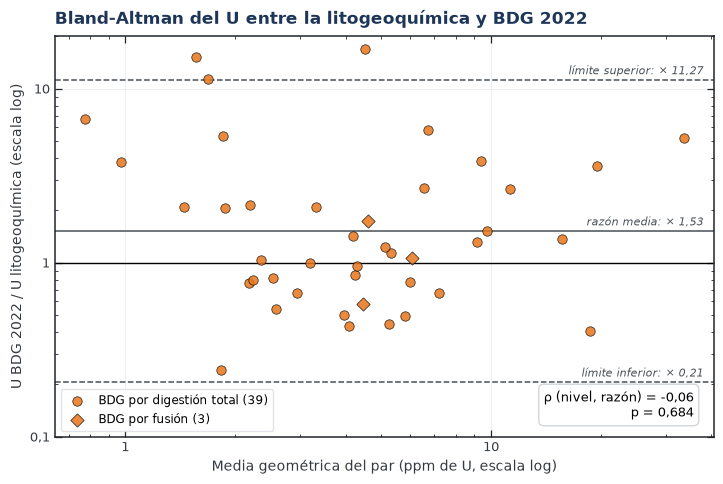

In [22]:
'''Figura 6: Bland-Altman del U (pares litogeoquímica - BDG 2022 a menos de 1 km)'''

fig, ax = plt.subplots(figsize=(8.5, 5.2))
for metodo, marcador in [('digestión total', 'o'), ('fusión', 'D')]:
    s = par.metodo_bdg.values == metodo
    ax.scatter(ba_u['media'][s], 10 ** ba_u['diferencia'][s], s=46, marker=marcador, color=graf.COLORES_FUENTE['BDG 2022'],
               alpha=0.85, edgecolor='black', lw=0.5, zorder=3, label=f'BDG por {metodo} ({s.sum()})')
for valor, texto, estilo in [(ba_u['sesgo'], 'razón media', '-'), (ba_u['lim_inf'], 'límite inferior', '--'),
                             (ba_u['lim_sup'], 'límite superior', '--')]:
    graf.linea_ref(ax, 10 ** valor, f'{texto}: × {graf.numero_es(10 ** valor, 2)}', pos=0.985, ls=estilo,
                   color=graf.GRIS)
ax.axhline(1, color='black', lw=1)
ax.set(xscale='log', yscale='log', xlabel='Media geométrica del par (ppm de U, escala log)',
       ylabel='U BDG 2022 / U litogeoquímica (escala log)')
ax.set_ylim(0.1, 20)
ax.legend(loc='lower left', fontsize=8.5)
graf.cuadro_texto(ax, f'ρ (nivel, razón) = {graf.numero_es(rho_nivel, 2)}\n{graf.texto_p(p_nivel)}')
ax.set_title('Bland-Altman del U entre la litogeoquímica y BDG 2022')
graf.marco(ax)
graf.ejes_log_planos(ax)

graf.guardar(fig, 'GC02_06_bland_altman_uranio.png', svg=True)

**Lectura:** el factor BDG / lito no depende de la concentración (ρ = −0,06; p = 0,68): la nube es horizontal entre
1 y 40 ppm, lo que descarta un problema de límite de detección. Lo que domina es la dispersión: los límites de
acuerdo van de × 0,21 a × 11, de modo que dos muestras a menos de 1 km pueden diferir cinco veces en cualquier
sentido. Esa variabilidad supera ampliamente a la analítica (los dos análisis de la réplica difieren en un factor de
1,46) e indica que, a esa distancia, las dos muestras suelen ser rocas distintas. Además, 37 de los 42 pares
corresponden a muestras de BDG tomadas en labores mineras, donde la roca suele estar alterada.

> La razón media (× 1,53) es mayor que la mediana (× 1,28) porque unos pocos pares con factores de 5 a 15 pesan más
> en la media; por ello se emplea la mediana para describir el sesgo.

***

<a id="parte-9"></a>

## <span style="color:#e8761a">**9. MÉTODO ANALÍTICO Y TIPO DE ROCA**</span>
***

BDG 2022 combina tres métodos: fusión (disuelve todo, incluido el circón, que aloja U), digestión total con cuatro
ácidos y digestión parcial (proyectos GE33-B6 y GE33B-5), que no disuelve el circón. Si el método influye, la
digestión parcial debe dar menos U:

In [23]:
'''U de BDG 2022 según el método analítico'''
METODOS_BDG = ['fusión', 'digestión total', 'digestión parcial']
por_metodo = [bdg.loc[bdg.metodo == m, 'U_ppm'] for m in METODOS_BDG]
h_kw, p_kw = stats.kruskal(*por_metodo)
p_total_parcial = stats.mannwhitneyu(por_metodo[1], por_metodo[2]).pvalue

resumen_metodo = estadistica.resumen_por_grupo(bdg, 'U_ppm', 'metodo', orden=METODOS_BDG)
resumen_metodo['proyectos'] = bdg.groupby('metodo').codigo.size().reindex(METODOS_BDG)
print(f'Kruskal-Wallis entre los tres métodos: H = {graf.numero_es(h_kw, 1)}, {graf.texto_p(p_kw)}')
print(f'Mann-Whitney digestión total frente a parcial: {graf.texto_p(p_total_parcial)}')
resumen_metodo.drop(columns='proyectos')

Kruskal-Wallis entre los tres métodos: H = 10,0, p = 0,007
Mann-Whitney digestión total frente a parcial: p = 0,002


,n_total,n_medido,mediana,P25,P75,min,max
metodo,,,,,,,
fusión,6,6,5.2,3.92,6.25,3.4,8.2
digestión total,172,172,4.1,2.70,7.85,0.4,76.7
digestión parcial,30,30,2.5,1.32,4.78,0.2,18.3


Las dos fuentes regionales tampoco muestrearon las mismas rocas. Como el U aumenta con el SiO₂ (GC01, figura 7), una
fuente con más granitos tendrá más U sin que exista sesgo analítico. Se compara el U dentro de cada clase de SiO₂:

In [24]:
'''Clases de SiO2 (rocas con SiO2 entre 40 y 80 %)'''
CLASES_SIO2 = ['básica\n(< 52 %)', 'intermedia\n(52-63 %)', 'ácida\n(63-70 %)', 'muy ácida\n(> 70 %)']
con_si = rocas[rocas.SiO2_pct.between(40, 80) & rocas.fuente.isin(['Litogeoquímica', 'BDG 2022'])].copy()
con_si['clase'] = pd.cut(con_si.SiO2_pct, [40, 52, 63, 70, 80], labels=CLASES_SIO2)

'''En cada clase: medianas, razón BDG / lito y prueba de Mann-Whitney'''
filas = []
for clase in CLASES_SIO2:
    a = con_si.loc[(con_si.clase == clase) & (con_si.fuente == 'Litogeoquímica'), 'U_ppm']
    b = con_si.loc[(con_si.clase == clase) & (con_si.fuente == 'BDG 2022'), 'U_ppm']
    filas.append({'clase': clase.replace('\n', ' '), 'n lito': len(a), 'n BDG': len(b), 'mediana lito': a.median(),
                  'mediana BDG': b.median(), 'razón BDG / lito': b.median() / a.median(),
                  'p de Mann-Whitney': stats.mannwhitneyu(a, b).pvalue})
por_clase = pd.DataFrame(filas).set_index('clase')
por_clase

,n lito,n BDG,mediana lito,mediana BDG,razón BDG / lito,p de Mann-Whitney
clase,,,,,,
básica (< 52 %),42,16,0.95,2.10,2.21,2.55e-04
intermedia (52-63 %),64,19,2.95,3.50,1.19,1.77e-01
ácida (63-70 %),90,40,3.90,4.55,1.17,4.36e-02
muy ácida (> 70 %),116,47,5.80,5.00,0.86,6.33e-01


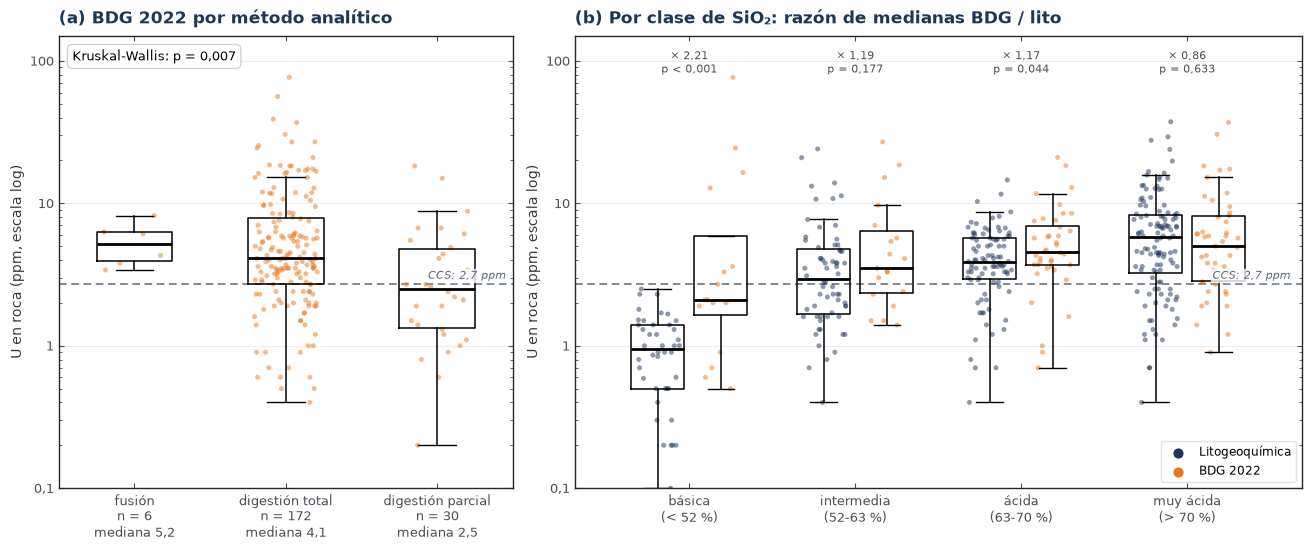

In [25]:
'''Figura 7: (a) U de BDG 2022 por método analítico y (b) U por clase de SiO2 en las dos fuentes regionales'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={'width_ratios': [1, 1.6]}, layout='constrained')
rng = np.random.default_rng(0)

def cajas(ax, valores, posiciones, color, ancho=0.32):
    '''Puntos de cada muestra y, encima, la caja con la mediana y los cuartiles'''
    for v, x in zip(valores, posiciones):
        ax.scatter(x + rng.uniform(-ancho / 2.4, ancho / 2.4, len(v)), v, s=13, color=color, alpha=0.5,
                   edgecolor='none', zorder=2)
    ax.boxplot(valores, positions=posiciones, widths=ancho, showfliers=False, zorder=3,
               medianprops=dict(color='black', lw=2), boxprops=dict(lw=1.1), whiskerprops=dict(lw=1.1))

'''(a) Métodos de BDG 2022'''
cajas(ax1, por_metodo, range(3), graf.COLORES_FUENTE['BDG 2022'], ancho=0.5)
ax1.set_xticks(range(3), [f'{m}\nn = {len(v)}\nmediana {graf.numero_es(v.median())}' for m, v in zip(METODOS_BDG, por_metodo)])
graf.linea_ref(ax1, graf.CCS['U'], 'CCS: 2,7 ppm', pos=0.985)
ax1.set(yscale='log', ylabel='U en roca (ppm, escala log)', ylim=(0.1, 150))
graf.cuadro_texto(ax1, f'Kruskal-Wallis: {graf.texto_p(p_kw)}', x=0.03, y=0.97, ha='left', va='top')
ax1.set_title('(a) BDG 2022 por método analítico')

'''(b) Litogeoquímica y BDG 2022 lado a lado en cada clase de SiO2'''
for k, fuente in enumerate(['Litogeoquímica', 'BDG 2022']):
    valores = [con_si.loc[(con_si.clase == c) & (con_si.fuente == fuente), 'U_ppm'] for c in CLASES_SIO2]
    cajas(ax2, valores, np.arange(4) + (k - 0.5) * 0.38, graf.COLORES_FUENTE[fuente])
    ax2.scatter([], [], s=40, color=graf.COLORES_FUENTE[fuente], label=fuente)
for i, clase in enumerate(CLASES_SIO2):
    f = por_clase.iloc[i]
    ax2.text(i, 120, f'× {graf.numero_es(f["razón BDG / lito"], 2)}\n{graf.texto_p(f["p de Mann-Whitney"])}',
             ha='center', va='top', fontsize=8, color=graf.GRIS)
ax2.set_xticks(range(4), CLASES_SIO2)
graf.linea_ref(ax2, graf.CCS['U'], 'CCS: 2,7 ppm', pos=0.985)
ax2.set(yscale='log', ylabel='U en roca (ppm, escala log)', ylim=(0.1, 150))
ax2.legend(loc='lower right', fontsize=8.5)
ax2.set_title('(b) Por clase de SiO₂: razón de medianas BDG / lito')

for ax in (ax1, ax2):
    ax.grid(axis='x', visible=False)
    graf.ejes_log_planos(ax, 'y')

graf.guardar(fig, 'GC02_07_metodo_y_litologia.png', svg=True)

**Lectura:** dentro de BDG 2022, la digestión parcial da menos U que la digestión total (mediana de 2,5 frente a
4,1 ppm; p = 0,002), como se espera si parte del U se aloja en circón que ese ataque no disuelve. El resultado no es
concluyente, porque cada método corresponde a proyectos y zonas distintos y las muestras con digestión parcial no
tienen SiO₂; aun así, justifica no mezclar sin advertencia los datos de ambos métodos.

Por tipo de roca, las dos fuentes coinciden en las rocas muy ácidas, que son las de interés para el uranio (× 0,86;
p = 0,63). En las intermedias y ácidas la diferencia es pequeña (× 1,17 a 1,19), comparable al sesgo de los pares. La
diferencia se concentra en las rocas básicas (× 2,2; p < 0,001) y no parece analítica: 15 de las 16 rocas básicas de
BDG proceden de labores mineras, y cuatro de ellas tienen más de 80 ppm de Th, valores impropios de un basalto o una
diorita que indican roca alterada o mineralizada.

***

<a id="parte-10"></a>

## <span style="color:#e8761a">**10. CONCLUSIONES DE LA VALIDACIÓN**</span>
***

| Fuente | Concordancia | Limitación principal | Uso recomendado |
|---|---|---|---|
| Estaciones de INGEMMET | Referencia: Bouguer simple con ρ = 2670 kg/m³ (sección 2) | Sin corrección de terreno; 3 valores de gravedad observada erróneos; cota no publicada | Valor local, solo a lo largo de las vías |
| XGM2019e en la superficie | r = 0,88; desviación de 26 mGal | Sesgo que cambia con la elevación (+30 a −20 mGal); resolución de ~9 km | Patrón regional y relleno de los vacíos entre estaciones |
| XGM2019e a h = 0 (grilla) | r = 0,80; desviación de 44 mGal | Error de ±66 mGal por encima de 3000 m | Mapas regionales, no comparación puntual |
| Litogeoquímica | Referencia regional de U | Método y año no siempre registrados | Fondo regional |
| BDG 2022 | × 1,2 a 1,5 respecto de la litogeoquímica; igual en las rocas muy ácidas | 89 % de las muestras en labores mineras; tres métodos analíticos | Junto con la litogeoquímica, separando la digestión parcial |
| GE27 | × 1,0 respecto de la litogeoquímica | Solo U; 13 vetas excluidas | Comparable con la litogeoquímica |
| IPEN y B-74 | Pocos pares | Muestreo dirigido a indicios (IPEN) y a vetas (B-74) | Validación local, no fondo regional |

**Pregunta 1.** XGM2019e reproduce la anomalía de Bouguer de las estaciones solo si se evalúa en la superficie:
la dispersión baja de 44 a 26 mGal y desaparece el error de las estaciones altas que en GC01 se había atribuido a la
campaña de medición. Persiste un sesgo que disminuye con la elevación, del orden de ±30 mGal, por lo que el modelo
describe bien el patrón regional, pero no sustituye a las mediciones en un estudio local.

**Pregunta 2.** El uranio de la litogeoquímica, BDG 2022 y GE27 es comparable en las rocas graníticas. BDG mide en
promedio un 30 % más que la litogeoquímica en el mismo lugar, sesgo moderado y apenas significativo que se explica
más por el muestreo (labores mineras y rocas básicas alteradas) que por el laboratorio; la digestión parcial de BDG
subestima el U. La variabilidad entre muestras cercanas (factores de 0,2 a 11) es mucho mayor que cualquier sesgo
entre fuentes: el principal error al integrar las fuentes no es analítico, sino de representatividad.

**Para GC03:** se emplean las rocas de caja depuradas (`lectura.rocas_de_caja`), las correlaciones se calculan por
fuente y la gravedad se toma de la grilla del modelo evaluada en la superficie del propio modelo
(`gravedad_XGM2019e_bouguer_superficie.tif`, calculada por el mismo script), que en las estaciones da r = 0,86 y
una desviación de 28 mGal, frente a 0,80 y 44 mGal de la grilla a h = 0.

Limitaciones: las estaciones no tienen cota medida (se usó el DEM), el DEM no tiene margen fuera del área, y los
pares entre fuentes son pocos fuera de la combinación litogeoquímica - BDG 2022.

***

<a id="ia"></a>

## <span style="color:#e8761a">**DECLARACIÓN DE USO DE INTELIGENCIA ARTIFICIAL**</span>
***

Se utilizó una herramienta de inteligencia artificial generativa como apoyo en la edición estética de las gráficas:
formato, paleta de colores, tipografía y composición de las figuras.

***

<a id="referencias"></a>

## <span style="color:#e8761a">**REFERENCIAS**</span>
***

- Barthelmes, F. (2013). [*Definition of functionals of the geopotential and their calculation from spherical harmonic models*](https://doi.org/10.2312/GFZ.b103-0902-26) (Scientific Technical Report STR09/02). GFZ Potsdam.
- Bland, J. M., y Altman, D. G. (1986). [Statistical methods for assessing agreement between two methods of clinical measurement](https://doi.org/10.1016/S0140-6736(86)90837-8). *The Lancet, 327*(8476), 307-310.
- Carpio et al. (2021). [*Prospección del litio en el norte y centro del Perú*](https://hdl.handle.net/20.500.12544/3542) (Boletín B-74). INGEMMET.
- Cuney, M. (2014). [Felsic magmatism and uranium deposits](https://doi.org/10.2113/gssgfbull.185.2.75). *Bulletin de la Société Géologique de France, 185*(2), 75-92.
- Hammer, S. (1939). [Terrain corrections for gravimeter stations](https://doi.org/10.1190/1.1440495). *Geophysics, 4*(3), 184-194.
- Hofmann-Wellenhof, B., y Moritz, H. (2006). [*Physical geodesy*](https://doi.org/10.1007/978-3-211-33545-1) (2.ª ed.). Springer.
- LaFehr, T. R. (1991). [Standardization in gravity reduction](https://doi.org/10.1190/1.1443137). *Geophysics, 56*(8), 1170-1178.
- Moritz, H. (2000). [Geodetic Reference System 1980](https://doi.org/10.1007/s001900050278). *Journal of Geodesy, 74*(1), 128-133.
- Rudnick, R. L., y Gao, S. (2003). [Composition of the continental crust](https://doi.org/10.1016/B0-08-043751-6/03016-4). En *Treatise on Geochemistry* (vol. 3, pp. 1-64). Elsevier.
- Zingerle, P., Pail, R., Gruber, T., y Oikonomidou, X. (2020). [The combined global gravity field model XGM2019e](https://doi.org/10.1007/s00190-020-01398-0). *Journal of Geodesy, 94*, 66.

***